# 02 · A first neural network: one neuron that forecasts 24 hours ahead

The smallest network that can do our task: **one neuron**.
It looks at the last 24 hours of one customer and predicts that customer's load
**24 hours after the window ends** (horizon h = 24, as in the paper's Table 2).

The same neuron, with the same 24 weights, is used for all 321 customers. This is exactly the
**AR (autoregressive) part of LSTNet** on its own. So this notebook is also the first step of
the baseline, and its error gives us a first row in the experiment table.

Steps:
1. Load and scale the data like the authors' code
2. Cut it into (input window, target) pairs
3. Define the network in PyTorch
4. Train it with gradient descent
5. Measure RSE and CORR on validation and test, and compare with a no-learning baseline

In [1]:
import numpy as np
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from pathlib import Path

torch.manual_seed(0)       # same random start every run, so results repeat
np.random.seed(0)
plt.rcParams["figure.dpi"] = 110
FIGS = Path("../results/figures")
FIGS.mkdir(parents=True, exist_ok=True)

## 1 · Load and scale

Each customer is divided by its own maximum (the authors' `normalize=2`), so every series lies
between 0 and 1. Without this, the biggest customers (200,000 kWh) would dominate the loss and
the smallest ones (11 kWh) would be ignored. We keep `scale` to turn predictions back into kWh.

In [2]:
raw = np.loadtxt("../data/electricity.txt.gz", delimiter=",")
T, n = raw.shape
scale = np.abs(raw).max(axis=0)
scale[scale == 0] = 1
data = (raw / scale).astype(np.float32)     # float32: what PyTorch uses by default
print(T, "hours ×", n, "customers; scaled range", data.min(), "to", data.max())

26304 hours × 321 customers; scaled range 0.0 to 1.0


## 2 · From one long table to (input, target) pairs

For a target at hour `t`:
* the **input** is the 24 hours that end `h` = 24 hours before it: rows `t-h-q+1 … t-h`
* the **target** is row `t` (all 321 customers at that hour)

The split is by the **target hour**: 60% train, 20% validation, 20% test, in time order.
An input window may reach back into the previous part; that is fine because those hours are
in the past.

We don't copy every window into memory (15,600 windows × 24 × 321 numbers would be about
0.5 GB). Instead a small `Dataset` class cuts each window out when it is asked for.

In [3]:
q = 24   # window length: how many past hours the neuron sees
h = 24   # horizon: how far after the window the target lies

class Windows(Dataset):
    """Pairs (x, y): x = q hours of all series, y = all series h hours after the window."""

    def __init__(self, data, target_hours):
        self.data = torch.from_numpy(data)
        self.targets = target_hours

    def __len__(self):
        return len(self.targets)

    def __getitem__(self, i):
        t = self.targets[i]
        x = self.data[t - h - q + 1 : t - h + 1]   # shape (q, n)
        y = self.data[t]                            # shape (n,)
        return x, y

train_end, valid_end = int(0.6 * T), int(0.8 * T)
first = q + h - 1                                   # earliest target with a full window
train_set = Windows(data, np.arange(first, train_end))
valid_set = Windows(data, np.arange(train_end, valid_end))
test_set = Windows(data, np.arange(valid_end, T))
print("windows: train", len(train_set), "| valid", len(valid_set), "| test", len(test_set))

x, y = train_set[0]
print("one input:", tuple(x.shape), " one target:", tuple(y.shape))

windows: train 15735 | valid 5261 | test 5261
one input: (24, 321)  one target: (321,)


## 3 · The network: one neuron, shared by all customers

`nn.Linear(q, 1)` is one neuron: 24 inputs, 24 weights, 1 bias, no activation function.

    prediction = w1·x(oldest hour) + … + w24·x(newest hour) + b

A batch arrives as (batch, q hours, n customers). We swap the last two axes to
(batch, n, q), so that every customer's 24-hour history is a row. `nn.Linear` then applies the
same neuron to each row, which gives (batch, n, 1); we drop the last axis.

In [4]:
class OneNeuron(nn.Module):
    def __init__(self, q):
        super().__init__()
        self.linear = nn.Linear(q, 1)

    def forward(self, x):                 # x: (batch, q, n)
        x = x.transpose(1, 2)             # -> (batch, n, q)
        return self.linear(x).squeeze(-1) # -> (batch, n)

model = OneNeuron(q)
n_params = sum(p.numel() for p in model.parameters())
print(model)
print("trainable numbers (parameters):", n_params)

OneNeuron(
  (linear): Linear(in_features=24, out_features=1, bias=True)
)
trainable numbers (parameters): 25


## 4 · Training

* **Loss:** mean absolute error (L1), the default in the authors' code. It is less sensitive
  to a few extreme hours than squared error.
* **Optimiser:** Adam with learning rate 0.001, also as in the authors' code.
* One **epoch** = one pass over all training windows, in shuffled batches of 128. Shuffling
  windows *inside* the training part is fine; we never mix training and test hours.
* After each epoch we check the validation loss and keep the best weights. This is how we
  choose a model without looking at the test set.

In [5]:
train_loader = DataLoader(train_set, batch_size=128, shuffle=True)
valid_loader = DataLoader(valid_set, batch_size=512)
test_loader = DataLoader(test_set, batch_size=512)

loss_fn = nn.L1Loss()
optimiser = torch.optim.Adam(model.parameters(), lr=1e-3)

def average_loss(loader):
    model.eval()                          # evaluation mode (matters later for dropout)
    total, count = 0.0, 0
    with torch.no_grad():                 # no gradients needed, just predictions
        for x, y in loader:
            total += loss_fn(model(x), y).item() * len(x)
            count += len(x)
    return total / count

history, best_valid, best_state = [], float("inf"), None
for epoch in range(1, 61):
    model.train()
    for x, y in train_loader:
        optimiser.zero_grad()             # 1. forget the gradients of the last step
        loss = loss_fn(model(x), y)       # 2. forward pass: predict and measure the error
        loss.backward()                   # 3. backpropagation: gradient of the loss for every weight
        optimiser.step()                  # 4. move each weight a small step downhill
    tr, va = average_loss(train_loader), average_loss(valid_loader)
    history.append((tr, va))
    if va < best_valid:
        best_valid = va
        best_state = {k: v.clone() for k, v in model.state_dict().items()}
    if epoch == 1 or epoch % 10 == 0:
        print(f"epoch {epoch:2d}  train L1 {tr:.4f}  valid L1 {va:.4f}")

model.load_state_dict(best_state)

epoch  1  train L1 0.0821  valid L1 0.0797


epoch 10  train L1 0.0453  valid L1 0.0451


epoch 20  train L1 0.0410  valid L1 0.0411


epoch 30  train L1 0.0402  valid L1 0.0404


epoch 40  train L1 0.0402  valid L1 0.0404


epoch 50  train L1 0.0401  valid L1 0.0403


epoch 60  train L1 0.0401  valid L1 0.0403


<All keys matched successfully>

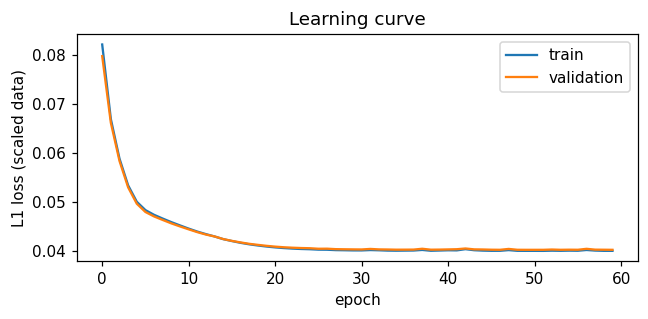

In [6]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot([a for a, _ in history], label="train")
ax.plot([b for _, b in history], label="validation")
ax.set_xlabel("epoch")
ax.set_ylabel("L1 loss (scaled data)")
ax.set_title("Learning curve")
ax.legend()
plt.tight_layout()
plt.show()

## 5 · Evaluation with the paper's metrics

Both metrics are computed on predictions turned back into kWh (multiplied by `scale`).

* **RSE** (lower is better): total squared error divided by the total squared distance of the
  targets from their mean. 1.0 would be no better than always predicting the average.
* **CORR** (higher is better): Pearson correlation between prediction and truth, per customer,
  then averaged. Customers whose test values never change (customer #182) are left out,
  because a correlation with a constant is undefined; the authors' code does the same.

As a **no-learning baseline** we use "same hour yesterday": the prediction for hour `t` is the
value at `t − 24`, which is the newest hour in the input window. A network that cannot beat
this has learned nothing useful.

In [7]:
def predict(loader):
    model.eval()
    preds, trues = [], []
    with torch.no_grad():
        for x, y in loader:
            preds.append(model(x))
            trues.append(y)
    return torch.cat(preds).numpy() * scale, torch.cat(trues).numpy() * scale

def same_hour_yesterday(dataset):
    # newest input hour = t - h = t - 24: the same clock hour one day earlier
    return np.stack([dataset[i][0][-1].numpy() for i in range(len(dataset))]) * scale

def rse(pred, true):
    return np.sqrt(((true - pred) ** 2).sum()) / np.sqrt(((true - true.mean()) ** 2).sum())

def corr(pred, true):
    sp, st = pred.std(axis=0), true.std(axis=0)
    keep = st != 0                                   # drop constant series
    c = ((pred - pred.mean(axis=0)) * (true - true.mean(axis=0))).mean(axis=0)
    return (c[keep] / (sp[keep] * st[keep])).mean(), (~keep).sum()

rows = []
for name, loader, dataset in [("validation", valid_loader, valid_set), ("test", test_loader, test_set)]:
    pred, true = predict(loader)
    naive = same_hour_yesterday(dataset)
    c_net, dropped = corr(pred, true)
    c_naive, _ = corr(naive, true)
    rows.append((name, rse(naive, true), c_naive, rse(pred, true), c_net, dropped))

print(f"{'split':<11}{'naive RSE':>10}{'naive CORR':>11}{'neuron RSE':>11}{'neuron CORR':>12}  dropped from CORR")
for r in rows:
    print(f"{r[0]:<11}{r[1]:>10.4f}{r[2]:>11.4f}{r[3]:>11.4f}{r[4]:>12.4f}  {r[5]}")
print("\npaper, Table 2, test, horizon 24: AR RSE 0.1054 / CORR 0.8595, LSTNet-Skip RSE 0.1007 / CORR 0.9119")

split       naive RSE naive CORR neuron RSE neuron CORR  dropped from CORR
validation     0.1104     0.8543     0.1063      0.8578  1
test           0.1048     0.8667     0.1032      0.8698  1

paper, Table 2, test, horizon 24: AR RSE 0.1054 / CORR 0.8595, LSTNet-Skip RSE 0.1007 / CORR 0.9119


## 6 · What did the neuron learn?

Each weight says how much one past hour counts. Large weights near the newest hour
(position 24 = the same clock hour yesterday) would mean the neuron mainly copies the
daily pattern.

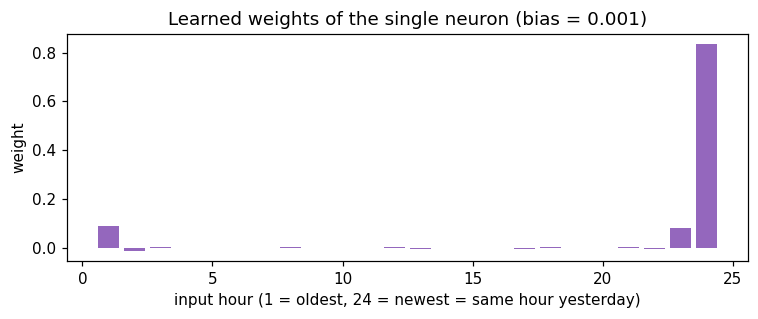

weight on newest hour: 0.834 | sum of all weights: 0.993


In [8]:
w = model.linear.weight.detach().numpy().ravel()
b = model.linear.bias.item()
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(np.arange(1, q + 1), w, color="tab:purple")
ax.set_xlabel("input hour (1 = oldest, 24 = newest = same hour yesterday)")
ax.set_ylabel("weight")
ax.set_title(f"Learned weights of the single neuron (bias = {b:.3f})")
plt.tight_layout()
fig.savefig(FIGS / "first_network_weights.png")
plt.show()
print("weight on newest hour:", round(float(w[-1]), 3), "| sum of all weights:", round(float(w.sum()), 3))

## 7 · Summary

One run, one seed, so treat these numbers as a first look, not a result.

| Model (test, horizon 24) | Parameters | RSE | CORR |
|---|---|---|---|
| Same hour yesterday (no learning) | 0 | 0.1048 | 0.8667 |
| One shared neuron, q = 24 (this notebook) | 25 | 0.1032 | 0.8698 |
| Paper: AR (one model per customer) | – | 0.1054 | 0.8595 |
| Paper: LSTNet-Skip | – | 0.1007 | 0.9119 |

* The loss stops improving after about 30 epochs; train and validation loss stay almost equal,
  so a model this small cannot overfit.
* The weights sum to about 1 and most of it sits on the newest hour: the neuron learned
  "take yesterday's value at this hour, smoothed a little with the hours around it".
* The "same hour yesterday" rule already reaches RSE 0.1048, slightly better than the paper's
  AR (0.1054). LSTNet-Skip (0.1007) is only about 4% better than this rule. That is the
  margin the deep part has to earn, which is the core question of the project.
* Next: the AR baseline as in the paper (one model per customer, lag chosen on validation),
  the shared `data.py` and `metrics.py`, then LSTNet-Skip.